# Can News Headlines Predict the Stock Market? Finding the bug behind an 86% accuracy

**The question:** every day, the 25 most popular world-news headlines on Reddit are paired with whether the Dow Jones index went up or down that day. A classic tutorial feeds the headlines to a random forest and reports **about 86% accuracy**. If that were real, it would be one of the most valuable models ever built. It is not real, and finding out why is the point of this notebook. *Where does the 86% come from, what is the honest score, can any model beat a coin toss, and could "up" days simply be easier to guess?*

> The folder was called "sports-sentiment" in the legacy repository, but the data has nothing to do with sports or sentiment: it is world news and stock-market direction, so the project is renamed `stock-news-direction`.

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit the data
4. Hypotheses and why we chose each test
5. A string-comparison bug in the split
6. H1: does the 86% survive a correct split?
7. H2: where exactly does the accuracy come from?
8. H3: can any model beat the base rate on later days?
9. Takeaways
10. Limitations

**Run it:** `uv run jupyter lab NLP/stock-news-direction/stock_news_direction.ipynb`, or *Run All* in any Jupyter. The data must be downloaded by hand from Kaggle (it needs a login): see the loader cell. It takes about 3 minutes on a CPU.

> **This is a teaching example about validation, not financial advice.**

## 1. 💡 The simple analogy

Imagine a **student who is given last year's exam to practise on**, and then is graded on... last year's exam.

- If part of the exam paper is also in the practice pack, the student scores 100% on those questions by **remembering the answers**, not by understanding anything.
- A **random forest** on word pairs is a superb rememberer: it can store "this exact day's headlines meant *up*". Give it the test days to study and it looks brilliant.
- An **honest test** keeps the exam strictly *after* everything the student studied. For markets, that means testing only on days **later** than every training day.
- And for a coin-toss problem, "brilliant" is only a few points above 50%: most of that is the market's habit of rising slightly more often than it falls (the **base rate**).

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed and the number of bootstrap draws keeps the notebook reproducible and avoids "magic numbers".

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.naive_bayes import MultinomialNB
from statsmodels.stats.proportion import proportion_confint

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
SEED = 365
N_BOOTSTRAP = 2_000
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if p < 1e-300 else f"{p:.1e}"

## 3. Audit the data first

*What:* load the table of trading days: for each day the 25 top headlines, and a label: **1** if the Dow Jones index rose or stayed level, **0** if it fell. We check how often the market rose, whether the labels have a memory (does an up day tend to follow an up day?), and how the base rate varies from year to year. *Why:* this tells us what a model must beat before we can call it skilful.

> **Problems in the legacy script this replaces:** it split the days with `data['Date'] < '20150101'`, comparing **text** dates ("2015-12-31") with a string without dashes (see the next section); it reported **accuracy** and a "precision" computed from the wrong cell of the confusion matrix; it tested on one 378-day stretch with no confidence interval, no baseline and no repeated validation; and the folder name ("sports sentiment") did not describe the data.

In [2]:
def load_news() -> pd.DataFrame:
    """Loads the daily news and market-direction table from ``data/``.

    The file is the Kaggle "Stock Sentiment / DJIA news" table: one row per trading day with the
    date, a label (1 if the Dow Jones index rose or stayed the same, 0 if it fell) and the 25
    top Reddit world-news headlines of the day (columns ``Top1`` to ``Top25``). Kaggle needs a
    login, so download it yourself and save it as ``data/Data.csv`` (or the Kaggle name
    ``data/Combined_News_DJIA.csv``).

    Returns:
        The table sorted by date, with an extra ``text`` column (all 25 headlines joined,
        lower-cased, letters only).

    Raises:
        FileNotFoundError: If neither file is present.
    """
    for name in ("Data.csv", "Combined_News_DJIA.csv"):
        path = DATA_DIR / name
        if path.exists():
            table = pd.read_csv(path, encoding="ISO-8859-1")
            break
    else:
        raise FileNotFoundError(
            "Download the DJIA news data from Kaggle (aaron7sun/stocknews, "
            "'Combined_News_DJIA.csv') and save it as data/Data.csv "
            "(columns: Date, Label, Top1 ... Top25)."
        )
    headline_cols = [f"Top{i}" for i in range(1, 26)]
    table["date"] = pd.to_datetime(table["Date"])
    table = table.sort_values("date").reset_index(drop=True)
    joined = table[headline_cols].fillna("").astype(str).agg(" ".join, axis=1)
    table["text"] = joined.map(lambda s: re.sub("[^a-zA-Z]", " ", s).lower())
    return table


news = load_news()
y = news["Label"].to_numpy()
print(f"{len(news):,} trading days, {news['date'].min().date()} to {news['date'].max().date()}")
print(f"Market rose or stayed level on {y.mean():.1%} of the days")
by_year = news.groupby(news["date"].dt.year)["Label"].agg(["mean", "size"])
print(
    "Share of up days by year: " + ", ".join(f"{yr} {v:.0%}" for yr, v in by_year["mean"].items())
)
rho1 = np.corrcoef(y[:-1], y[1:])[0, 1]
runs = 1 + (np.diff(y) != 0).sum()
n1, n0 = y.sum(), len(y) - y.sum()
expected_runs = 1 + 2 * n1 * n0 / (n1 + n0)
sd_runs = np.sqrt(2 * n1 * n0 * (2 * n1 * n0 - n1 - n0) / ((n1 + n0) ** 2 * (n1 + n0 - 1)))
z = (runs - expected_runs) / sd_runs
print(
    f"Day-to-day: correlation of one day's label with the next = {rho1:+.3f}; "
    f"runs test z = {z:+.2f}, p = {2 * stats.norm.sf(abs(z)):.2f}"
)

4,101 trading days, 2000-01-03 to 2016-07-01
Market rose or stayed level on 52.8% of the days
Share of up days by year: 2000 52%, 2001 50%, 2002 44%, 2003 55%, 2004 52%, 2005 53%, 2006 56%, 2007 58%, 2008 47%, 2009 54%, 2010 57%, 2011 55%, 2012 49%, 2013 58%, 2014 55%, 2015 48%, 2016 56%
Day-to-day: correlation of one day's label with the next = -0.055; runs test z = +3.48, p = 0.00


**How to read this:**

- **4,101 trading days** from 2000-01-03 to 2016-07-01. The market **rose or stayed level on 52.8%** of them, so always guessing "up" would already score 52.8%.
- **The base rate moves with the years:** from **44%** up days in 2002 and **47%** in 2008 to **58%** in 2007 and 2013. In the test stretch used later (2015 to mid-2016) it is **50.8%**.
- **The labels have a faint negative memory:** the correlation between one day's label and the next is **-0.055**, and the runs test has z = **+3.48** (p < 0.001), meaning the market flips direction slightly *more* often than chance. So "tomorrow = today" is, if anything, a slightly bad guess.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does the legacy 86% survive a correct, chronological split? | Accuracy no better than always guessing the commoner label | Higher | Exact binomial test against the commoner-label rate; Wilson intervals |
| H2 | Is the accuracy coming from days the model has already seen? | Accuracy is the same on days in and not in training | Differs | Accuracy split by whether the test day is in the training set; a dose-response run that adds more and more of the test period to training |
| H3 | Can any model beat the base rate on later days? | Accuracy no better than 50% (or than the commoner label) | Higher | Expanding-window validation over 6 later blocks (3,516 days); binomial tests |

*Why these tests?* Each test day is a yes/no outcome, so the number of correct days follows a **binomial** distribution if the model is only guessing. The test is *exact*, needs no normality and takes the size of the test set into account (378 days can only pin accuracy down to about ±5 points). The **expanding window** is the honest way to validate a time series: train on the past, test on the future, repeat.

## 5. A string-comparison bug in the split

*What:* the legacy script wrote `train = data[data['Date'] < '20150101']` and `test = data[data['Date'] > '20141231']`. The dates in the file look like `2015-12-31`, and Python compares text **character by character**. At the fifth character, `-` sorts *before* `0`, so any 2015 date counts as "less than" `20150101`. We check exactly which days end up where, and then build the proper split using real dates.

In [3]:
legacy_train = news[news["Date"] < "20150101"]  # exactly what the legacy script wrote
legacy_test = news[news["Date"] > "20141231"]
print(
    f"'2015-12-31' < '20150101' is {'2015-12-31' < '20150101'} "
    "(text is compared character by character: '-' sorts before '0')"
)
print(
    f"Legacy training days: {len(legacy_train):,}, from {legacy_train['date'].min().date()} to "
    f"{legacy_train['date'].max().date()}"
)
print(
    f"Legacy test days: {len(legacy_test):,}, from {legacy_test['date'].min().date()} to "
    f"{legacy_test['date'].max().date()}"
)
overlap = legacy_test[legacy_test["date"].isin(legacy_train["date"])]
print(
    f"Test days that are also training days: {len(overlap)} of {len(legacy_test)} "
    f"({len(overlap) / len(legacy_test):.1%})"
)

cut = pd.Timestamp("2015-01-01")
train = news[news["date"] < cut]
test = news[news["date"] >= cut]
print(
    f"\nProper split: {len(train):,} training days to {train['date'].max().date()}, "
    f"{len(test)} test days from {test['date'].min().date()}; "
    f"test days that are also training days: {int(test['date'].isin(train['date']).sum())}"
)
print(f"Share of up days in the test period: {test['Label'].mean():.1%}")

'2015-12-31' < '20150101' is True (text is compared character by character: '-' sorts before '0')
Legacy training days: 3,975, from 2000-01-03 to 2015-12-31
Legacy test days: 378, from 2015-01-02 to 2016-07-01
Test days that are also training days: 252 of 378 (66.7%)

Proper split: 3,723 training days to 2014-12-31, 378 test days from 2015-01-02; test days that are also training days: 0
Share of up days in the test period: 50.8%


**How to read this:**

- `'2015-12-31' < '20150101'` is **True**: the comparison happens character by character, and `-` sorts before `0`.
- So the legacy **training set runs from 2000-01-03 to 2015-12-31**: **3,975 days**, including every day of 2015. The legacy **test set** starts on 2015-01-02 and holds **378 days**.
- **252 of the 378 test days (66.7%) are also in the training set.** Two thirds of the exam was in the practice pack.
- The **proper split** has 3,723 training days (to 2014-12-31) and the same 378 test days, with **no** overlap. In that stretch the market rose on **50.8%** of days.

## 6. H1: does the 86% survive a correct split?

*What:* the legacy model, exactly as written (bigram word counts of the day's 25 headlines, a random forest of 200 trees with the entropy criterion), trained and tested on the **same 378 test days** in two ways: with the legacy split and with the proper one. For each we report accuracy with a 95% Wilson interval and an exact binomial test against "always guess the commoner label" in that period. *Why:* it isolates the effect of the split: nothing else changes.

In [4]:
def make_forest() -> RandomForestClassifier:
    """The legacy classifier: 200 trees, entropy criterion."""
    return RandomForestClassifier(
        n_estimators=200, criterion="entropy", n_jobs=-1, random_state=SEED
    )


def fit_score(train_frame: pd.DataFrame, test_frame: pd.DataFrame) -> tuple:
    """Fits the legacy recipe (bigram counts and a random forest) and predicts the test days.

    Args:
        train_frame: Days to learn from.
        test_frame: Days to predict.

    Returns:
        The predictions and the fitted vectoriser and forest.
    """
    vec = CountVectorizer(ngram_range=(2, 2))
    forest = make_forest().fit(vec.fit_transform(train_frame["text"]), train_frame["Label"])
    return forest.predict(vec.transform(test_frame["text"])), vec, forest


legacy_pred, _, _ = fit_score(legacy_train, legacy_test)
proper_pred, _, _ = fit_score(train, test)
rows = []
for name, truth, pred in [
    ("legacy split (2015 in training)", legacy_test["Label"].to_numpy(), legacy_pred),
    ("proper split (nothing from 2015 in training)", test["Label"].to_numpy(), proper_pred),
]:
    hits = int((pred == truth).sum())
    low, high = proportion_confint(hits, len(truth), method="wilson")
    majority = max(truth.mean(), 1 - truth.mean())
    binom = stats.binomtest(hits, len(truth), majority, alternative="greater")
    rows.append(
        {
            "setting": name,
            "test days": len(truth),
            "accuracy": hits / len(truth),
            "ci_low": low,
            "ci_high": high,
            "always the commoner label": majority,
            "p vs commoner label": binom.pvalue,
        }
    )
h1 = pd.DataFrame(rows).set_index("setting")
print(h1.round(3).to_string())
print("\nLegacy confusion matrix (rows: truth down/up, columns: predicted down/up):")
print(confusion_matrix(legacy_test["Label"], legacy_pred))
print("Proper split confusion matrix:")
print(confusion_matrix(test["Label"], proper_pred))

                                              test days  accuracy  ci_low  ci_high  always the commoner label  p vs commoner label
setting                                                                                                                           
legacy split (2015 in training)                     378     0.860   0.821    0.891                      0.508                0.000
proper split (nothing from 2015 in training)        378     0.526   0.476    0.576                      0.508                0.252

Legacy confusion matrix (rows: truth down/up, columns: predicted down/up):
[[141  45]
 [  8 184]]
Proper split confusion matrix:
[[ 18 168]
 [ 11 181]]


**How to read this:**

- **Legacy split: 86.0% accuracy** (95% CI 82.1% to 89.1%) on 378 days, far above the 50.8% you get by always guessing "up" (p < 0.001). The confusion matrix shows it: 141 of 186 down days and 184 of 192 up days called correctly.
- **Proper split: 52.6%** (95% CI 47.6% to 57.6%): the exact binomial test against the commoner-label rate has **p = 0.25**, so **we fail to reject H₀**. The model is indistinguishable from guessing. Its confusion matrix shows why: it calls **168 of the 186 down days "up"**, so it is mostly guessing the commoner label.
- **The 33-point drop from 86.0% to 52.6% is the leak, nothing else:** same model, same test days, same code. Only the training set changed.

## 7. H2: where exactly does the accuracy come from?

*What:* two checks on the legacy model. (1) Split its test days into the **252 that are in its training set** and the **126 that are not**, and measure accuracy on each. (2) A **dose-response** experiment: train on the proper training days plus the first 0%, 25%, 50%, 75% or 100% of the test days, and score the model on all test days. If the accuracy comes from memory, it should rise steadily with the dose. *Why:* a real skill would not care whether the test days were in training.

In [5]:
in_train = legacy_test["date"].isin(legacy_train["date"]).to_numpy()
truth = legacy_test["Label"].to_numpy()
rows = []
for name, mask in [
    ("test days also in the legacy training set", in_train),
    ("test days not in the legacy training set", ~in_train),
]:
    hits = int((legacy_pred[mask] == truth[mask]).sum())
    low, high = proportion_confint(hits, int(mask.sum()), method="wilson")
    rows.append(
        {
            "group": name,
            "days": int(mask.sum()),
            "accuracy": hits / mask.sum(),
            "ci_low": low,
            "ci_high": high,
        }
    )
split_acc = pd.DataFrame(rows).set_index("group")
print(split_acc.round(3).to_string())

# dose-response: put a growing share of the test period into training
fractions = [0.0, 0.25, 0.5, 0.75, 1.0]
dose_rows = []
for frac in fractions:
    n_in = int(round(frac * len(test)))
    added, held = test.iloc[:n_in], test.iloc[n_in:]
    pred, _, _ = fit_score(pd.concat([train, added]), test)
    truth_all = test["Label"].to_numpy()
    seen = np.arange(len(test)) < n_in
    dose_rows.append(
        {
            "share of the test period in training": frac,
            "accuracy on all test days": (pred == truth_all).mean(),
            "on days in training": (pred[seen] == truth_all[seen]).mean() if seen.any() else np.nan,
            "on days not in training": (pred[~seen] == truth_all[~seen]).mean()
            if (~seen).any()
            else np.nan,
        }
    )
dose = pd.DataFrame(dose_rows).set_index("share of the test period in training")
print("\nAccuracy as more of the test period leaks into training:")
print(dose.round(3).to_string())

                                           days  accuracy  ci_low  ci_high
group                                                                     
test days also in the legacy training set   252     1.000   0.985    1.000
test days not in the legacy training set    126     0.579   0.492    0.662



Accuracy as more of the test period leaks into training:
                                      accuracy on all test days  on days in training  on days not in training
share of the test period in training                                                                         
0.00                                                      0.526                  NaN                    0.526
0.25                                                      0.646                  1.0                    0.528
0.50                                                      0.796                  1.0                    0.593
0.75                                                      0.902                  1.0                    0.606
1.00                                                      1.000                  1.0                      NaN


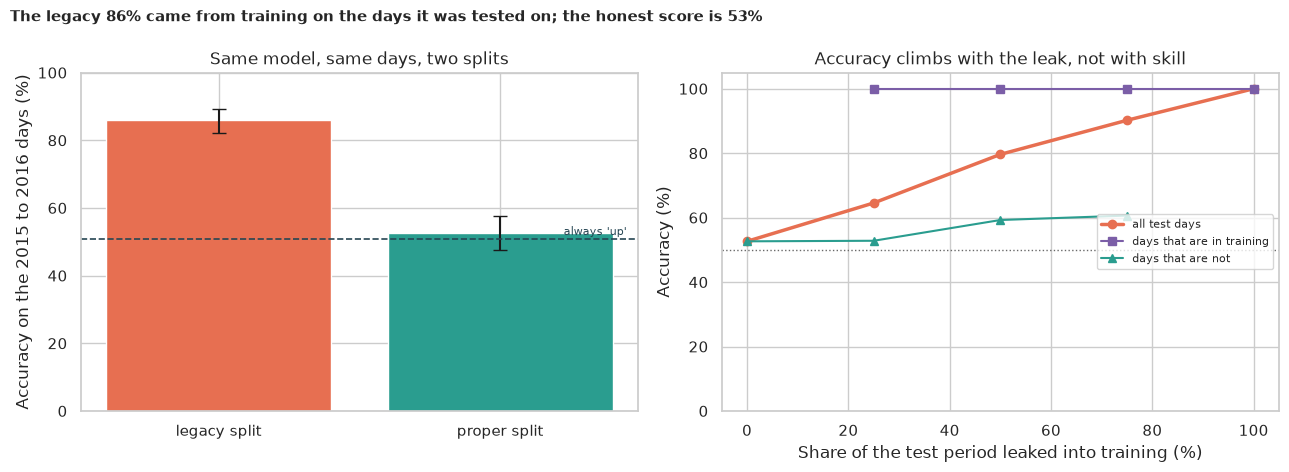

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(
    ["legacy split", "proper split"],
    h1["accuracy"] * 100,
    color=[ORANGE, TEAL],
    yerr=[(h1["accuracy"] - h1["ci_low"]) * 100, (h1["ci_high"] - h1["accuracy"]) * 100],
    capsize=5,
)
axes[0].axhline(test["Label"].mean() * 100, color=NAVY, ls="--", lw=1.2)
axes[0].text(
    1.45, test["Label"].mean() * 100 + 1.2, "always 'up'", color=NAVY, ha="right", fontsize=8
)
axes[0].set_ylabel("Accuracy on the 2015 to 2016 days (%)")
axes[0].set_ylim(0, 100)
axes[0].set_title("Same model, same days, two splits")
axes[1].plot(
    dose.index * 100,
    dose["accuracy on all test days"] * 100,
    marker="o",
    color=ORANGE,
    lw=2.5,
    label="all test days",
)
axes[1].plot(
    dose.index * 100,
    dose["on days in training"] * 100,
    marker="s",
    color=PURPLE,
    lw=1.5,
    label="days that are in training",
)
axes[1].plot(
    dose.index * 100,
    dose["on days not in training"] * 100,
    marker="^",
    color=TEAL,
    lw=1.5,
    label="days that are not",
)
axes[1].axhline(50, color="dimgray", ls=":", lw=1)
axes[1].set_xlabel("Share of the test period leaked into training (%)")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(0, 105)
axes[1].set_title("Accuracy climbs with the leak, not with skill")
axes[1].legend(fontsize=8, loc="center right")
fig.suptitle(
    f"The legacy {h1.iloc[0]['accuracy'] * 100:.0f}% came from training on the days it "
    f"was tested on; the honest score is {h1.iloc[1]['accuracy'] * 100:.0f}%",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_leak.png", dpi=150)
plt.show()

**How to read this:**

- **On the 252 days that are in its training set the model is right 100% of the time** (95% CI 98.5% to 100%). It has simply memorised them: one day's 25 headlines are a fingerprint that the forest can look up.
- **On the 126 days that are not in its training set, 57.9%** (95% CI 49.2% to 66.2%), consistent with a coin toss (and with the base rate). Blending the two gives (252 x 100% + 126 x 57.9%) / 378 ≈ 86%: the legacy number, almost exactly.
- **The dose-response is clean:** overall accuracy is **52.6%** with none of the test period in training, **64.6%** with a quarter, **79.6%** with half, **90.2%** with three quarters and **100%** with all of it. The leaked days are always right (100%), and nothing else explains the climb.
- **A small caution:** on days *not* in training, accuracy drifts up from 52.8% to 60.6% as more of the nearby days are added, which may be a hint that market regimes persist for a few months, but those groups have only 95 to 284 days, so the intervals are wide (plus or minus 6 to 10 points) and we do not read it as evidence of skill.

## 8. H3: can any model beat the base rate on later days?

*What:* an **expanding-window** validation: the 4,101 days are cut into 7 consecutive blocks; we train on the first *k* blocks and test on block *k+1*, for *k* = 1 to 6, so every model is always tested on days **later** than everything it learned from. That gives **3,516 predicted days**. The models: always guessing the commoner label of the training period, "yesterday's direction", Naive Bayes on word counts, logistic regression on TF-IDF of words and word pairs, and the legacy random forest. We compare each with 50% using an exact binomial test, with Wilson intervals. *Why:* with 3,516 days the intervals are about ±1.7 points: tight enough to say what is and is not there.

In [7]:
edges = np.linspace(0, len(news), 8).astype(int)  # 7 chronological blocks
cv_rows = []
models = {
    "always the commoner label": None,
    "yesterday's direction": None,
    "Naive Bayes on word counts": lambda: (
        CountVectorizer(ngram_range=(1, 1), min_df=2),
        MultinomialNB(),
    ),
    "logistic regression on TF-IDF": lambda: (
        TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True),
        LogisticRegression(C=1.0, max_iter=2000),
    ),
    "random forest on bigrams (legacy)": None,
}
for k in range(1, 7):  # train on blocks 0..k-1, test on block k
    tr, te = news.iloc[: edges[k]], news.iloc[edges[k] : edges[k + 1]]
    truth = te["Label"].to_numpy()
    preds = {
        "always the commoner label": np.full(len(te), int(tr["Label"].mean() >= 0.5)),
        "yesterday's direction": news["Label"]
        .shift(1)
        .iloc[edges[k] : edges[k + 1]]
        .to_numpy()
        .astype(int),
    }
    for name in ("Naive Bayes on word counts", "logistic regression on TF-IDF"):
        vec, clf = models[name]()
        clf.fit(vec.fit_transform(tr["text"]), tr["Label"])
        preds[name] = clf.predict(vec.transform(te["text"]))
    preds["random forest on bigrams (legacy)"], _, _ = fit_score(tr, te)
    for name, pred in preds.items():
        cv_rows.append(
            {
                "fold": k,
                "model": name,
                "n": len(te),
                "hits": int((pred == truth).sum()),
                "accuracy": (pred == truth).mean(),
                "up_share": truth.mean(),
            }
        )
cv = pd.DataFrame(cv_rows)
pooled = cv.groupby("model", sort=False).agg(n=("n", "sum"), hits=("hits", "sum"))
pooled["accuracy"] = pooled["hits"] / pooled["n"]
pooled[["ci_low", "ci_high"]] = [
    proportion_confint(h, n, method="wilson")
    for h, n in zip(pooled["hits"], pooled["n"], strict=True)
]
pooled["p vs 50%"] = [
    stats.binomtest(int(h), int(n), 0.5).pvalue
    for h, n in zip(pooled["hits"], pooled["n"], strict=True)
]
print(
    f"Expanding-window validation: 6 later blocks of about {int(cv['n'].iloc[0])} days each "
    f"({int(pooled['n'].iloc[0]):,} days predicted in all)"
)
print(pooled.round(3).to_string())
print("\nAccuracy by fold:")
print(cv.pivot(index="fold", columns="model", values="accuracy")[list(models)].round(3).to_string())

Expanding-window validation: 6 later blocks of about 586 days each (3,516 days predicted in all)
                                      n  hits  accuracy  ci_low  ci_high  p vs 50%
model                                                                             
always the commoner label          3516  1871     0.532   0.516    0.549     0.000
yesterday's direction              3516  1664     0.473   0.457    0.490     0.002
Naive Bayes on word counts         3516  1731     0.492   0.476    0.509     0.371
logistic regression on TF-IDF      3516  1832     0.521   0.505    0.538     0.013
random forest on bigrams (legacy)  3516  1840     0.523   0.507    0.540     0.006

Accuracy by fold:
model  always the commoner label  yesterday's direction  Naive Bayes on word counts  logistic regression on TF-IDF  random forest on bigrams (legacy)
fold                                                                                                                                                 
1  

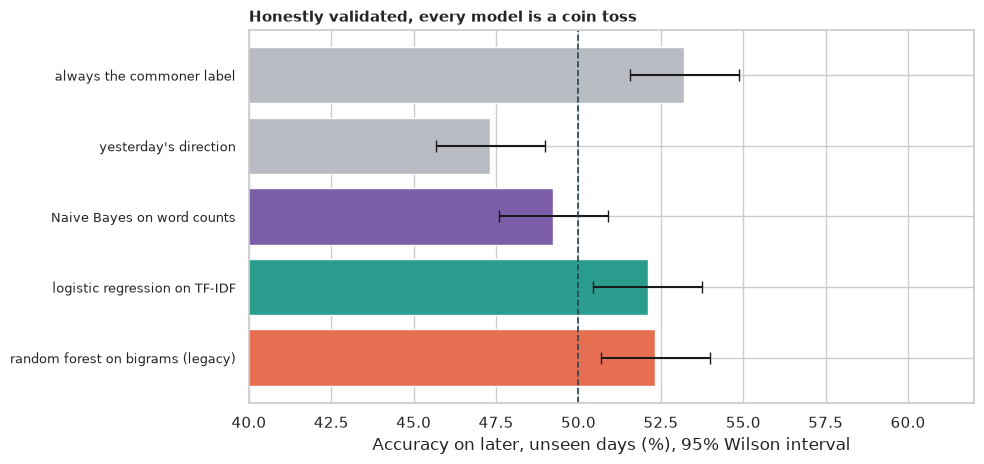

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.8))
order = list(models)
colors_ = [GREY, GREY, PURPLE, TEAL, ORANGE]
ypos = np.arange(len(order))[::-1]
ax.barh(
    ypos,
    pooled.loc[order, "accuracy"] * 100,
    color=colors_,
    xerr=[
        (pooled.loc[order, "accuracy"] - pooled.loc[order, "ci_low"]) * 100,
        (pooled.loc[order, "ci_high"] - pooled.loc[order, "accuracy"]) * 100,
    ],
    capsize=4,
)
ax.axvline(50, color=NAVY, ls="--", lw=1.2)
ax.set_yticks(ypos, order, fontsize=9)
ax.set_xlim(40, 62)
ax.set_xlabel("Accuracy on later, unseen days (%), 95% Wilson interval")
ax.set_title(
    "Honestly validated, every model is a coin toss", loc="left", fontweight="bold", fontsize=11
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_honest_models.png", dpi=150)
plt.show()

**How to read this (pooled over 3,516 later days):**

- **Always guessing the commoner label scores 53.2%** (95% CI 51.6% to 54.9%): the market's tendency to rise is worth about three points before any model is involved.
- **No model beats that:** logistic regression **52.1%** (50.5% to 53.8%), the legacy random forest **52.3%** (50.7% to 54.0%), Naive Bayes **49.2%** (47.6% to 50.9%, p = 0.37 against 50%). The two that are statistically above 50% (p = 0.013 and 0.006) are **below** the always-the-commoner-label benchmark, so whatever they have is the base rate, not the headlines. **We fail to reject H₀** for any model beating the base rate.
- **"Yesterday's direction" scores only 47.3%** (45.7% to 49.0%; p = 0.002 against 50%), significantly *below* a coin toss, in line with the negative memory found in the audit: the market flips slightly more often than it repeats.
- **No fold is special:** the headline models range between 44.5% and 56.0% fold by fold, around 50% every time.
- **Conclusion:** these 25 daily headlines contain no usable signal about the same day's index direction: what looks like skill is the base rate, or leakage.

## 9. 🎯 Takeaways

1. **The 86% was a split bug.** Comparing dates as text (`'2015-12-31' < '20150101'` is `True`) put all of 2015 into training, so **252 of the 378 test days (66.7%) were in the training set**.
2. **The honest score is a coin toss:** 52.6% (CI 47.6% to 57.6%) on the same test days, against 50.8% for always guessing "up" (p = 0.25).
3. **The leak is perfectly traceable:** the model is right on 100% of test days it saw in training, 57.9% on those it did not, and the accuracy rises smoothly from 52.6% to 100% as more of the test period is added to training.
4. **Over 3,516 later days no model beat the base rate:** the commoner label scores 53.2%, the legacy forest 52.3%, logistic regression 52.1%, and "yesterday's direction" a significant 47.3%.
5. **Always parse dates, and always compare with a baseline.** A big number should trigger a hunt for leakage before any celebration.

## 10. ⚠️ Limitations

- **One news source (Reddit's top world-news headlines) and one index (the Dow Jones).** We do not claim that no news predicts any market, only that these headlines do not predict this label.
- **We know only the up/down label,** not the size of moves or the date and time of the headlines relative to the close, so we cannot check whether the headlines were published before or after the move.
- **Bag-of-words models only.** A modern language model reading the headlines might find something, though the base-rate and leakage checks above would still apply.
- **The expanding-window blocks are about 586 days each** and the six folds overlap in their training data, so the pooled intervals treat the days as independent; they are a little optimistic.
- **Accuracy ignores trading costs and the size of moves.** A model with 54% accuracy can still lose money.
- **The data file must be downloaded by hand** from Kaggle (it needs a login), so the notebook cannot fetch it automatically.
- **This is a teaching example about validation, not financial advice.**